# Internações hospitalares no SUS (SIH/RD) — 2022 a 2024

Notebook do Projeto Final, Parte 1. Reprodução: rode antes `python src/coleta.py` (veja o README).

## 1. Coleta

In [1]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRONZE = ROOT / "data" / "bronze"
meta = pd.read_csv(ROOT / "reports" / "metadados_coleta.csv")
meta["ano"] = 2000 + meta["arquivo"].str[4:6].astype(int)
meta["uf"] = meta["arquivo"].str[2:4]
meta.head()

,arquivo,url,baixado_em,status,linhas,colunas_dbf,hash_colunas,bytes_dbc,bytes_parquet,ano,uf
0,RDAC2201.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:14,ok,3977,113,f7e9456918,285026,237069,2022,AC
1,RDAC2202.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:16,ok,3703,113,f7e9456918,267860,223222,2022,AC
2,RDAC2203.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:17,ok,4185,113,f7e9456918,295808,243667,2022,AC
3,RDAC2204.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:18,ok,4183,113,f7e9456918,299035,245509,2022,AC
4,RDAC2205.dbc,ftp://ftp.datasus.gov.br/dissemin/publicos/SIH...,2026-11-08T03:08:19,ok,5283,113,f7e9456918,367106,296814,2022,AC


### 1.1 Volume coletado

In [2]:
ok = meta[meta.status == "ok"]
resumo = pd.DataFrame({
    "arquivos ok": [len(ok)],
    "arquivos pendentes": [int((meta.status != "ok").sum())],
    "linhas": [int(ok.linhas.sum())],
    "DBC (MB)": [round(ok.bytes_dbc.sum() / 1e6, 1)],
    "Parquet (MB)": [round(ok.bytes_parquet.sum() / 1e6, 1)],
})
display(resumo)
display(ok.groupby("ano").agg(arquivos=("arquivo", "count"), linhas=("linhas", "sum")))

,arquivos ok,arquivos pendentes,linhas,DBC (MB),Parquet (MB)
0,972,0,40048092,3007.4,2117.6


,arquivos,linhas
ano,,
2022,324,12520914
2023,324,13355814
2024,324,14171364


### 1.2 Mudança de layout entre anos

Cada arquivo guarda um hash da lista de colunas do DBF. Mais de um hash por ano indica mudança de layout.

In [3]:
layout = ok.groupby(["ano", "hash_colunas", "colunas_dbf"]).size().rename("arquivos").reset_index()
display(layout)

import pyarrow.parquet as pq
cols_by_hash = {}
for h, grp in ok.groupby("hash_colunas"):
    f = grp.iloc[0]
    path = BRONZE / "sih_rd" / f"ano={f.ano}" / f"uf={f.uf}" / f.arquivo.replace(".dbc", ".parquet")
    cols_by_hash[h] = set(pq.read_schema(path).names)
base = next(iter(cols_by_hash.values()))
for h, cols in cols_by_hash.items():
    print(h, "a mais:", sorted(cols - base), "a menos:", sorted(base - cols))

,ano,hash_colunas,colunas_dbf,arquivos
0,2022,f7e9456918,113,324
1,2023,f7e9456918,113,324
2,2024,f7e9456918,113,324


f7e9456918 a mais: [] a menos: []


### 1.3 CSV × Parquet

Amostra: SP, 2023 (12 arquivos). O CSV é gravado como a fonte costuma vir, com separador `;` e encoding latin-1.

In [4]:
sample_dir = BRONZE / "sih_rd" / "ano=2023" / "uf=SP"
df = pd.concat(pd.read_parquet(p) for p in sorted(sample_dir.glob("*.parquet")))
bench = BRONZE / "bench"
bench.mkdir(exist_ok=True)
csv_path, pq_path = bench / "sp2023.csv", bench / "sp2023.parquet"
df.to_csv(csv_path, sep=";", encoding="latin-1", index=False)
df.to_parquet(pq_path, index=False)

def timed(fn, reps=3):
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return min(t)

cols = ["MUNIC_RES", "DIAG_PRINC", "VAL_TOT", "DIAS_PERM"]
res = pd.DataFrame({
    "formato": ["CSV", "Parquet"],
    "tamanho (MB)": [csv_path.stat().st_size / 1e6, pq_path.stat().st_size / 1e6],
    "leitura completa (s)": [timed(lambda: pd.read_csv(csv_path, sep=";", encoding="latin-1", dtype=str)),
                             timed(lambda: pd.read_parquet(pq_path))],
    "leitura de 4 colunas (s)": [timed(lambda: pd.read_csv(csv_path, sep=";", encoding="latin-1", dtype=str, usecols=cols)),
                                 timed(lambda: pd.read_parquet(pq_path, columns=cols))],
}).round(2)
print(f"{len(df):,} linhas × {df.shape[1]} colunas")
res

2,674,138 linhas × 113 colunas


,formato,tamanho (MB),leitura completa (s),leitura de 4 colunas (s)
0,CSV,1265.35,39.57,9.26
1,Parquet,128.90,10.87,0.83


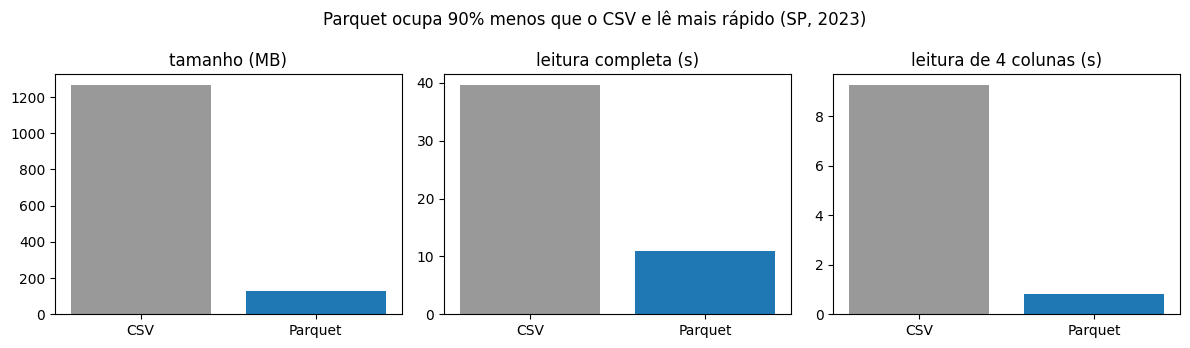

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, res.columns[1:]):
    ax.bar(res.formato, res[col], color=["#999999", "#1f77b4"])
    ax.set_title(col)
reducao = 1 - res.loc[1, "tamanho (MB)"] / res.loc[0, "tamanho (MB)"]
fig.suptitle(f"Parquet ocupa {reducao:.0%} menos que o CSV e lê mais rápido (SP, 2023)")
plt.tight_layout()

### 1.4 Dificuldades da fonte

- **FTP instável:** conexões caem e o servidor recusa conexões paralelas (`425 Cannot open data connection`). Por isso o download é sequencial, com até 5 tentativas e espera exponencial, grava em `.part` e confere o tamanho.
- **Formato DBC:** é um DBF comprimido em formato proprietário e exige o `pyreaddbc`. O `dbfread` converte datas e números por padrão e quebra em data impossível; usamos um parser que devolve texto cru.
- **Documentação espalhada:** o dicionário está num PDF (`IT_SIHSUS_1603.pdf`) e as tabelas de conversão em `.cnv` de largura fixa do TabWin. O `CID10CSV.zip` citado em materiais antigos não existe mais no FTP.
- **População:** o IBGE não publica estimativa municipal para 2023, então esse ano é interpolado (veja o dicionário).
- **Layout entre anos:** resultado na seção 1.2.

## 2. Análise exploratória (sobre o bronze)

A EDA vem antes da limpeza. Lemos o bronze como está (tudo texto) e fazemos conversões só para analisar. O Spark processa a base inteira; o pandas trabalha com agregados e com uma amostra de 1%.

In [6]:
import numpy as np
import seaborn as sns
from pyspark import StorageLevel
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[*]").appName("eda")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())

raw = (spark.read.option("mergeSchema", "true").parquet(str(BRONZE / "sih_rd"))
       .withColumnRenamed("uf", "uf_hospital"))
print(len(raw.columns), "colunas (incluindo ano e uf_hospital, que vêm da partição)")

COLS = ["ANO_CMPT", "MES_CMPT", "UF_ZI", "MUNIC_RES", "MUNIC_MOV", "NASC", "SEXO", "IDADE", "COD_IDADE",
        "DT_INTER", "DT_SAIDA", "DIAG_PRINC", "PROC_REA", "CAR_INT", "DIAS_PERM", "UTI_MES_TO", "VAL_TOT",
        "MORTE", "CNES", "N_AIH", "IDENT", "RACA_COR"]
UF_SIGLA = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA",
            "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA",
            "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS", "50": "MS",
            "51": "MT", "52": "GO", "53": "DF"}
REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}
SIGLA_COD = {v: k for k, v in UF_SIGLA.items()}

uf_map = F.create_map(*[F.lit(x) for kv in UF_SIGLA.items() for x in kv])
reg_map = F.create_map(*[F.lit(x) for kv in REGIAO.items() for x in kv])
sig_map = F.create_map(*[F.lit(x) for kv in SIGLA_COD.items() for x in kv])

# colunas de apoio só para a análise; a limpeza de verdade é no tratamento.py
age = (F.when(F.col("COD_IDADE") == "4", F.col("IDADE").cast("int"))
        .when(F.col("COD_IDADE").isin("2", "3"), F.lit(0))
        .when(F.col("COD_IDADE") == "5", F.col("IDADE").cast("int") + 100))
df = (raw.select("ano", "uf_hospital", *COLS)
      .withColumn("idade_anos", age)
      .withColumn("uf_residencia", uf_map[F.substring("MUNIC_RES", 1, 2)])
      .withColumn("regiao_residencia", reg_map[F.substring("MUNIC_RES", 1, 1)])
      .withColumn("regiao_hospital", reg_map[F.substring(sig_map[F.col("uf_hospital")], 1, 1)])
      .withColumn("val_tot", F.col("VAL_TOT").cast("double"))
      .withColumn("dias_perm", F.col("DIAS_PERM").cast("int"))
      .withColumn("uti_mes_to", F.col("UTI_MES_TO").cast("int"))
      .withColumn("dt_inter", F.to_date("DT_INTER", "yyyyMMdd"))
      .withColumn("dt_saida", F.to_date("DT_SAIDA", "yyyyMMdd"))
      .withColumn("cid3", F.substring("DIAG_PRINC", 1, 3))
      .persist(StorageLevel.DISK_ONLY))
N = df.count()
print(f"{N:,} linhas")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/08 13:12:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


115 colunas (incluindo ano e uf_hospital, que vêm da partição)


26/11/08 13:12:39 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


40,048,092 linhas


### 2.1 Visão geral

In [7]:
por_ano = df.groupBy("ano").count().orderBy("ano").toPandas()
display(por_ano)
amostra = raw.select(*COLS).sample(fraction=0.01, seed=42).toPandas()
print(f"amostra: {len(amostra):,} linhas")

,ano,count
0,2022,12520914
1,2023,13355814
2,2024,14171364


amostra: 401,503 linhas


In [8]:
ESPERADO = {"ANO_CMPT": "int", "MES_CMPT": "int", "UF_ZI": "código", "MUNIC_RES": "código", "MUNIC_MOV": "código",
            "NASC": "data", "SEXO": "categórico", "IDADE": "int", "COD_IDADE": "categórico", "DT_INTER": "data",
            "DT_SAIDA": "data", "DIAG_PRINC": "código", "PROC_REA": "código", "CAR_INT": "categórico",
            "DIAS_PERM": "int", "UTI_MES_TO": "int", "VAL_TOT": "decimal", "MORTE": "categórico",
            "CNES": "código", "N_AIH": "código", "IDENT": "categórico", "RACA_COR": "categórico"}

def inferir(s):
    s = s.dropna().astype(str)
    s = s[s != ""]
    if pd.to_datetime(s, format="%Y%m%d", errors="coerce").notna().mean() > 0.99 and s.str.len().eq(8).all():
        return "data"
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > 0.99:
        return "int" if (num.dropna() % 1 == 0).all() and not s.str.contains(r"\.").any() else "decimal"
    return "texto"

# bytes por coluna no Parquet: soma dos column chunks de todos os arquivos
pq_bytes = {}
for p in (BRONZE / "sih_rd").rglob("*.parquet"):
    md_ = pq.ParquetFile(p).metadata
    for rg in range(md_.num_row_groups):
        for c in range(md_.num_columns):
            col = md_.row_group(rg).column(c)
            pq_bytes[col.path_in_schema] = pq_bytes.get(col.path_in_schema, 0) + col.total_compressed_size

mem = amostra.memory_usage(deep=True, index=False) / len(amostra) * N
tipos = pd.DataFrame({
    "tipo inferido": {c: inferir(amostra[c]) for c in COLS},
    "tipo esperado": ESPERADO,
    "memória pandas estimada (MB)": (mem / 1e6).round(0),
    "Parquet (MB)": {c: round(pq_bytes.get(c, 0) / 1e6, 1) for c in COLS},
    "cardinalidade (amostra)": amostra.nunique(),
})
tipos["confere?"] = [
    "sim" if (e in (i, "categórico", "código") and i in ("int", "texto", "decimal") and e != "data") or e == i else "não"
    for i, e in zip(tipos["tipo inferido"], tipos["tipo esperado"])]
tipos

,tipo inferido,tipo esperado,memória pandas estimada (MB),Parquet (MB),cardinalidade (amostra),confere?
ANO_CMPT,int,int,2123.0,0.1,3,sim
MES_CMPT,int,int,2042.0,0.1,12,sim
UF_ZI,int,código,2203.0,0.7,2311,sim
MUNIC_RES,int,código,2203.0,33.4,5560,sim
MUNIC_MOV,int,código,2203.0,3.9,3093,sim
NASC,data,data,2283.0,189.0,36108,sim
SEXO,int,categórico,2002.0,5.5,2,sim
IDADE,int,int,2038.0,35.8,100,sim
COD_IDADE,int,categórico,2002.0,2.9,4,sim
DT_INTER,data,data,2283.0,42.6,1773,sim


Todas as colunas chegam como texto (o bronze não converte nada). A memória em pandas como `object` é várias vezes maior que o Parquet, e isso justifica tipar na silver: `int8`/`int16` para códigos pequenos, `date` e `category`. O layout é o mesmo nos 3 anos (seção 1.2), então a matriz de colunas por ano dá 113 colunas em todos.

### 2.2 Qualidade: ausentes, duplicados e valores fora do domínio

,ano,2022,2023,2024
coluna,tipo,,,
COD_IDADE,sentinela,0.000,0.000,0.000
VAL_TOT,sentinela,0.302,0.323,0.306
RACA_COR,sentinela,19.227,2.759,0.017


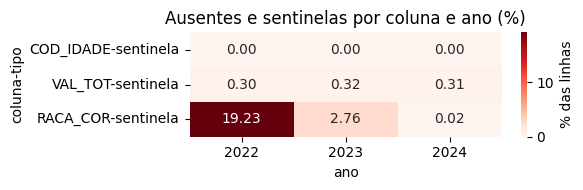

In [9]:
# códigos que na prática significam "não informado"
SENTINELAS = {"SEXO": ["0", "9"], "COD_IDADE": ["0"], "RACA_COR": ["99"], "CAR_INT": ["99"],
              "MUNIC_RES": ["000000"], "NASC": ["00000000"], "VAL_TOT": ["0", "0.00"], "CNES": ["0000000"]}
aggs = []
for c in COLS:
    aggs.append(F.avg((F.col(c).isNull() | (F.trim(c) == "")).cast("int")).alias(f"{c}|vazio"))
    if c in SENTINELAS:
        aggs.append(F.avg(F.col(c).isin(SENTINELAS[c]).cast("int")).alias(f"{c}|sentinela"))
aus = df.groupBy("ano").agg(*aggs).orderBy("ano").toPandas().set_index("ano").T * 100
aus.index = pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in aus.index], names=["coluna", "tipo"])
aus_rel = aus[(aus > 0).any(axis=1)].round(3)
display(aus_rel)
fig, ax = plt.subplots(figsize=(6, max(2, 0.4 * len(aus_rel))))
sns.heatmap(aus_rel, annot=True, fmt=".2f", cmap="Reds", ax=ax, cbar_kws={"label": "% das linhas"})
ax.set_title("Ausentes e sentinelas por coluna e ano (%)")
plt.tight_layout()

In [10]:
h = raw.select(F.xxhash64(*[F.col(c) for c in raw.columns if c not in ("ano", "uf_hospital")] , "uf_hospital").alias("h"))
exatos = N - h.distinct().count()
aih = df.groupBy("N_AIH").agg(F.count("*").alias("n"), F.sum((F.col("IDENT") == "5").cast("int")).alias("n5"))
dup = aih.agg(F.sum(F.when(F.col("n") > 1, F.col("n") - 1).otherwise(0)).alias("repeticoes_aih"),
              F.sum(F.when((F.col("n") > 1) & (F.col("n5") == 0), F.col("n") - 1).otherwise(0)).alias("repeticoes_sem_ident5")).first()
ident = df.groupBy("IDENT").count().toPandas()
print(f"duplicados exatos (todas as colunas): {exatos:,}")
print(f"N_AIH repetido: {dup.repeticoes_aih:,} linhas extras; sem nenhuma AIH tipo 5 no grupo: {dup.repeticoes_sem_ident5:,}")
ident

duplicados exatos (todas as colunas): 0
N_AIH repetido: 406,408 linhas extras; sem nenhuma AIH tipo 5 no grupo: 0


,IDENT,count
0,1,39630392
1,5,417700


In [11]:
cid_ok = spark.read.parquet(str(BRONZE / "aux" / "cid10.parquet")).select(F.col("cid").alias("cid3")).withColumn("cid_ok", F.lit(1))
mun_ok = (spark.read.parquet(str(BRONZE / "aux" / "municipios.parquet"))
          .select(F.col("cod_municipio_6").alias("MUNIC_RES")).withColumn("mun_ok", F.lit(1)))
chk = df.join(F.broadcast(cid_ok), "cid3", "left").join(F.broadcast(mun_ok), "MUNIC_RES", "left")
regras = {
    "SEXO fora de {1, 2, 3}": ~F.col("SEXO").isin("1", "2", "3"),
    "DT_INTER inválida": F.col("dt_inter").isNull(),
    "DT_SAIDA inválida": F.col("dt_saida").isNull(),
    "NASC inválida": F.to_date("NASC", "yyyyMMdd").isNull(),
    "DT_SAIDA antes de DT_INTER": F.col("dt_saida") < F.col("dt_inter"),
    "NASC depois de DT_INTER": F.to_date("NASC", "yyyyMMdd") > F.col("dt_inter"),
    "idade nula após conversão": F.col("idade_anos").isNull(),
    "idade > 120": F.col("idade_anos") > 120,
    "DIAG_PRINC fora da CID-10 (3 car.)": F.col("cid_ok").isNull(),
    "MUNIC_RES fora da tabela de municípios": F.col("mun_ok").isNull(),
    "MUNIC_RES sem UF válida": F.col("uf_residencia").isNull(),
    "VAL_TOT <= 0": F.col("val_tot") <= 0,
    "DIAS_PERM > 365": F.col("dias_perm") > 365,
    "DIAS_PERM ≠ DT_SAIDA − DT_INTER": F.col("dias_perm") != F.datediff("dt_saida", "dt_inter"),
    "competência ≠ ano da partição": F.col("ANO_CMPT").cast("int") != F.col("ano"),
}
dom = chk.agg(*[F.sum(F.coalesce(cond, F.lit(False)).cast("int")).alias(nome) for nome, cond in regras.items()]).toPandas().T
dom.columns = ["linhas"]
dom["%"] = (dom["linhas"] / N * 100).round(4)
dom.sort_values("linhas", ascending=False)

,linhas,%
DIAS_PERM ≠ DT_SAIDA − DT_INTER,413848,1.0334
VAL_TOT <= 0,124309,0.3104
idade > 120,444,0.0011
DIAG_PRINC fora da CID-10 (3 car.),184,0.0005
idade nula após conversão,10,0.0000
DT_INTER inválida,0,0.0000
"SEXO fora de {1, 2, 3}",0,0.0000
NASC depois de DT_INTER,0,0.0000
DT_SAIDA antes de DT_INTER,0,0.0000
NASC inválida,0,0.0000


In [12]:
# exemplos de CIDs e municípios que não casaram
display(chk.filter(F.col("cid_ok").isNull()).groupBy("DIAG_PRINC").count().orderBy(F.desc("count")).limit(10).toPandas())
display(chk.filter(F.col("mun_ok").isNull()).groupBy("MUNIC_RES").count().orderBy(F.desc("count")).limit(10).toPandas())

,DIAG_PRINC,count
0,U109,94
1,U10,37
2,U099,29
3,U09,24


,MUNIC_RES,count


### 2.3 Análise univariada

In [13]:
num = ["val_tot", "dias_perm", "uti_mes_to", "idade_anos"]
q = df.select(*num).summary("count", "mean", "stddev", "min", "1%", "25%", "50%", "75%", "99%", "max").toPandas().set_index("summary").astype(float)
q.loc["IQR"] = q.loc["75%"] - q.loc["25%"]
display(q.round(2))

out = {}
for c in num:
    m, s, q1, q3 = q.loc["mean", c], q.loc["stddev", c], q.loc["25%", c], q.loc["75%", c]
    iqr = q3 - q1
    out[c] = df.agg(
        F.sum(((F.col(c) < q1 - 1.5 * iqr) | (F.col(c) > q3 + 1.5 * iqr)).cast("int")).alias("IQR (1,5×)"),
        F.sum((F.abs((F.col(c) - m) / s) > 3).cast("int")).alias("z-score (|z|>3)"),
    ).first().asDict()
outl = pd.DataFrame(out).T
outl["% IQR"] = (outl["IQR (1,5×)"] / N * 100).round(2)
outl["% z"] = (outl["z-score (|z|>3)"] / N * 100).round(2)
outl

,val_tot,dias_perm,uti_mes_to,idade_anos
summary,,,,
count,40048092.00,40048092.00,40048092.00,40048082.00
mean,1583.52,5.09,0.61,42.36
stddev,3910.81,7.47,3.12,24.79
min,0.00,0.00,0.00,0.00
1%,44.22,0.00,0.00,0.00
25%,355.54,1.00,0.00,24.00
50%,632.48,3.00,0.00,41.00
75%,1126.01,6.00,0.00,63.00
99%,17984.38,33.00,15.00,91.00


,"IQR (1,5×)",z-score (|z|>3),% IQR,% z
val_tot,5402233,646034,13.49,1.61
dias_perm,3515429,1188672,8.78,2.97
uti_mes_to,3514574,782801,8.78,1.95
idade_anos,390,604,0.00,0.00


procedimentos mais comuns entre os 1% maiores VAL_TOT:


,PROC_REA,count
0,0303010037,42054
1,0415010012,38683
2,0406010935,38008
3,0303160063,19722
4,0406010692,16558
5,0415020034,14217
6,0303160055,14002
7,0303140151,13093


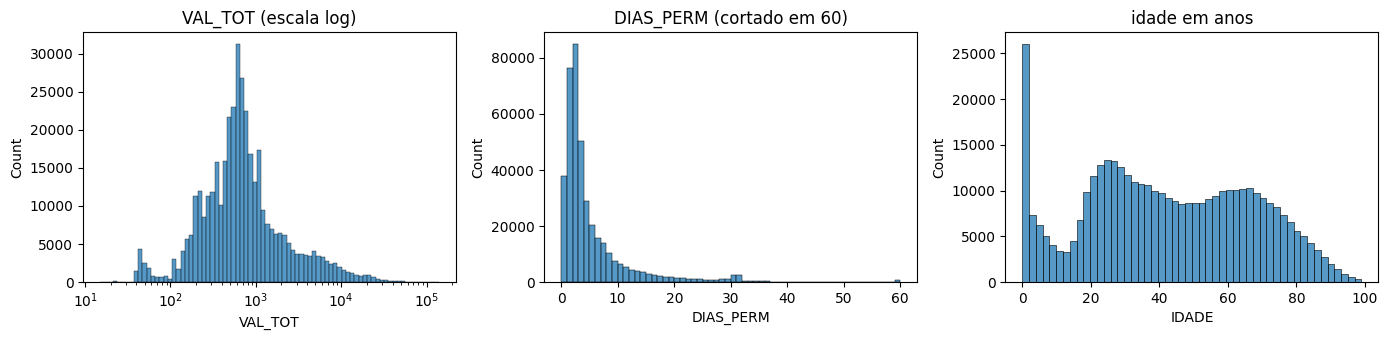

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(amostra["VAL_TOT"].astype(float), bins=80, log_scale=(True, False), ax=axes[0]).set_title("VAL_TOT (escala log)")
sns.histplot(amostra["DIAS_PERM"].astype(int).clip(upper=60), bins=60, ax=axes[1]).set_title("DIAS_PERM (cortado em 60)")
idade_am = amostra["IDADE"].astype(int).where(amostra["COD_IDADE"] == "4", 0)
sns.histplot(idade_am, bins=50, ax=axes[2]).set_title("idade em anos")
plt.tight_layout()

top_val = (df.filter(F.col("val_tot") > q.loc["99%", "val_tot"]).groupBy("PROC_REA").count()
           .orderBy(F.desc("count")).limit(8).toPandas())
print("procedimentos mais comuns entre os 1% maiores VAL_TOT:")
top_val

Os outliers de `VAL_TOT` e `DIAS_PERM` se concentram em procedimentos de alta complexidade (UTI, transplantes, neonatologia, longa permanência psiquiátrica). Portanto são **fenômeno real** e não erro, e por isso a limpeza vai **marcar** esses casos sem removê-los, usando IQR por procedimento. A distribuição é muito assimétrica (média muito acima da mediana): o z-score, que supõe normalidade, marca menos casos que o IQR e é pouco adequado aqui. Casos como `DIAS_PERM > 365` e `VAL_TOT <= 0` são suspeitos de erro ou registro administrativo e aparecem na tabela de domínio.

In [15]:
cats = ["SEXO", "COD_IDADE", "IDENT", "CAR_INT", "MORTE", "RACA_COR", "uf_hospital"]
freqs = {c: df.groupBy(c).count().orderBy(F.desc("count")).toPandas() for c in cats}
for c, t in freqs.items():
    t["%"] = (t["count"] / N * 100).round(2)
    print(c, "— cardinalidade", len(t)); display(t.head(8))
card = df.agg(*[F.approx_count_distinct(c).alias(c) for c in ["DIAG_PRINC", "cid3", "PROC_REA", "MUNIC_RES", "CNES"]]).toPandas()
print("cardinalidade aproximada:"); card

SEXO — cardinalidade 2


,SEXO,count,%
0,3,22790013,56.91
1,1,17258079,43.09


COD_IDADE — cardinalidade 5


,COD_IDADE,count,%
0,4,37959296,94.78
1,2,1223551,3.06
2,3,834431,2.08
3,5,30804,0.08
4,0,10,0.00


IDENT — cardinalidade 2


,IDENT,count,%
0,1,39630392,98.96
1,5,417700,1.04


... (6 outputs left out)

uf_hospital — cardinalidade 27


,uf_hospital,count,%
0,SP,8065896,20.14
1,MG,4343313,10.85
2,PR,2859706,7.14
3,BA,2681093,6.69
4,RJ,2594594,6.48
5,RS,2414326,6.03
6,PE,1886992,4.71
7,SC,1767357,4.41


cardinalidade aproximada:


,DIAG_PRINC,cid3,PROC_REA,MUNIC_RES,CNES
0,10664,1700,1793,5492,5125


### 2.4 Análise bivariada e temporal

ano,2022,2023,2024,var 22→24 (%)
regiao_residencia,,,,
Centro-Oeste,1003992,1098160,1164219,16.0
Nordeste,3323497,3507900,3699390,11.3
Norte,1062469,1137553,1175778,10.7
Sudeste,4942684,5280901,5613294,13.6
Sul,2188272,2331300,2518683,15.1


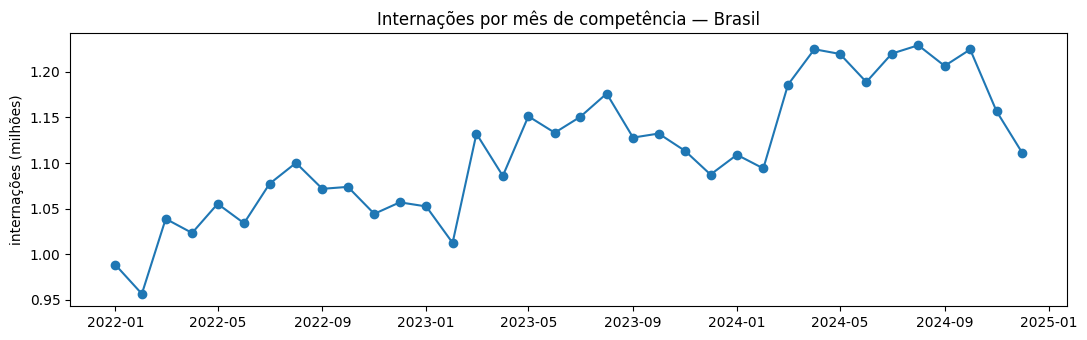

In [16]:
mensal = (df.groupBy(F.col("ANO_CMPT"), F.col("MES_CMPT")).count()
          .withColumn("data", F.to_date(F.concat_ws("-", "ANO_CMPT", "MES_CMPT", F.lit("01"))))
          .orderBy("data").toPandas())
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(mensal["data"], mensal["count"] / 1e6, marker="o")
ax.set_ylabel("internações (milhões)"); ax.set_title("Internações por mês de competência — Brasil")
plt.tight_layout()

reg = df.groupBy("ano", "regiao_residencia").count().toPandas().pivot(index="regiao_residencia", columns="ano", values="count")
reg["var 22→24 (%)"] = ((reg[2024] / reg[2022] - 1) * 100).round(1)
reg

In [17]:
ufs = (df.groupBy("uf_residencia").count().withColumnRenamed("count", "por residência")
       .join(df.groupBy("uf_hospital").count().withColumnRenamed("count", "por hospital")
             .withColumnRenamed("uf_hospital", "uf_residencia"), "uf_residencia", "outer").toPandas()
       .rename(columns={"uf_residencia": "UF"}).set_index("UF").sort_values("por hospital", ascending=False))
ufs["saldo (hospital − residência)"] = ufs["por hospital"] - ufs["por residência"]
ufs

,por residência,por hospital,saldo (hospital − residência)
UF,,,
SP,8022542,8065896,43354
MG,4359492,4343313,-16179
PR,2851842,2859706,7864
BA,2700098,2681093,-19005
RJ,2595036,2594594,-442
RS,2416758,2414326,-2432
PE,1865238,1886992,21754
SC,1769655,1767357,-2298
CE,1674916,1675755,839


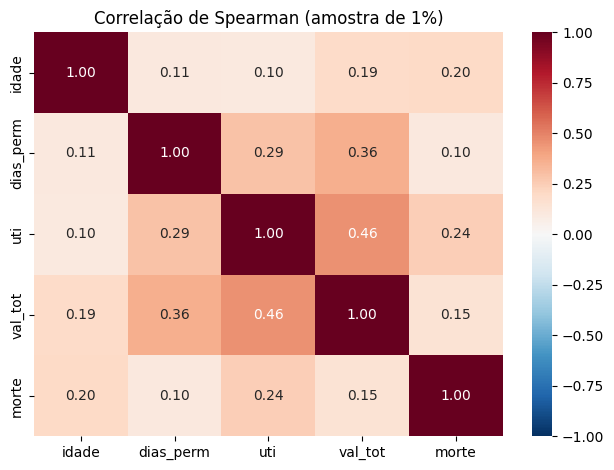

In [18]:
am = amostra.assign(val_tot=amostra.VAL_TOT.astype(float), dias_perm=amostra.DIAS_PERM.astype(int),
                    uti=amostra.UTI_MES_TO.astype(int), idade=idade_am, morte=amostra.MORTE.astype(int))
corr = am[["idade", "dias_perm", "uti", "val_tot", "morte"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlação de Spearman (amostra de 1%)"); plt.tight_layout()

In [19]:
cap = spark.read.parquet(str(BRONZE / "aux" / "cid10.parquet")).select(F.col("cid").alias("cid3"), "capitulo")
dfc = df.join(F.broadcast(cap), "cid3", "left").withColumn("capitulo", F.coalesce("capitulo", F.lit("ignorado")))
faixa = (F.when(F.col("idade_anos") < 15, "0-14").when(F.col("idade_anos") < 60, "15-59")
          .when(F.col("idade_anos").isNotNull(), "60+").otherwise("ignorado"))

sexo_cap = dfc.groupBy("capitulo").pivot("SEXO").count().toPandas().set_index("capitulo").fillna(0)
display((sexo_cap.div(sexo_cap.sum(axis=1), axis=0) * 100).round(1).sort_index())

fx_obito = dfc.groupBy(faixa.alias("faixa")).agg(F.count("*").alias("internacoes"), F.avg(F.col("MORTE").cast("int")).alias("letalidade")).toPandas()
fx_obito["letalidade"] = (fx_obito["letalidade"] * 100).round(2)
display(fx_obito.sort_values("faixa"))

reg_cap = dfc.groupBy("capitulo").pivot("regiao_residencia").count().toPandas().set_index("capitulo").fillna(0)
(reg_cap / reg_cap.sum() * 100).round(1)

,1,3
capitulo,,
I. Algumas doenças infecciosas e parasitárias,52.3,47.7
II. Neoplasias (tumores),40.5,59.5
III. Doenças sangue órgãos hemat e transt imunitár,46.1,53.9
IV. Doenças endócrinas nutricionais e metabólicas,48.7,51.3
IX. Doenças do aparelho circulatório,52.4,47.6
V. Transtornos mentais e comportamentais,60.2,39.8
VI. Doenças do sistema nervoso,47.6,52.4
VII. Doenças do olho e anexos,46.5,53.5
VIII.Doenças do ouvido e da apófise mastóide,48.3,51.7


,faixa,internacoes,letalidade
0,0-14,5668549,1.20
1,15-59,22646986,1.97
2,60+,11732547,11.11
3,ignorado,10,10.00


,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
capitulo,,,,,
VIII.Doenças do ouvido e da apófise mastóide,0.2,0.2,0.2,0.2,0.2
XII. Doenças da pele e do tecido subcutâneo,1.7,3.0,2.4,2.2,1.9
XIX. Lesões enven e alg out conseq causas externas,13.4,10.8,11.8,10.6,10.8
XXII.Códigos para propósitos especiais,0.0,0.0,0.0,0.0,0.0
VI. Doenças do sistema nervoso,1.9,1.6,1.1,2.3,2.2
XVIII.Sint sinais e achad anorm ex clín e laborat,2.0,2.0,1.4,2.0,2.0
XIV. Doenças do aparelho geniturinário,6.9,6.9,7.3,7.9,7.0
XXI. Contatos com serviços de saúde,3.3,3.0,3.0,3.2,2.6
XVII.Malf cong deformid e anomalias cromossômicas,0.6,0.6,0.7,0.7,0.6


### 2.5 Respostas preliminares às perguntas de pesquisa

In [20]:
pop = pd.read_parquet(BRONZE / "ibge" / "populacao_municipio_ano.parquet")
pop["uf_residencia"] = pop["cod_municipio_7"].str[:2].map(UF_SIGLA)
pop_uf = pop.groupby(["uf_residencia", "ano"]).populacao.sum()

# P1: taxa bruta por 100 mil, por UF de residência e ano (contando só AIH principal, sem IDENT=5)
p1 = df.filter(F.col("IDENT") != "5").groupBy("uf_residencia", "ano").count().toPandas().dropna()
p1 = p1.join(pop_uf, on=["uf_residencia", "ano"])
p1["taxa_100mil"] = p1["count"] / p1["populacao"] * 1e5
p1w = p1.pivot(index="uf_residencia", columns="ano", values="taxa_100mil").round(0)
p1w["var %"] = ((p1w[2024] / p1w[2022] - 1) * 100).round(1)
print("P1 — taxa bruta por 100 mil (UF de residência)")
display(p1w.sort_values(2024, ascending=False))
saz = mensal.assign(mes=pd.to_datetime(mensal.data).dt.month).groupby("mes")["count"].mean()
print("P1 — mês com mais internações em média:", saz.idxmax(), "| com menos:", saz.idxmin())

P1 — taxa bruta por 100 mil (UF de residência)


ano,2022,2023,2024,var %
uf_residencia,,,,
PR,7511.0,7952.0,8610.0,14.6
SC,6987.0,7436.0,8057.0,15.3
RO,7611.0,7756.0,7695.0,1.1
MS,7081.0,7514.0,7478.0,5.6
ES,6865.0,7254.0,7473.0,8.9
RS,7115.0,7239.0,7372.0,3.6
MG,6556.0,6864.0,7300.0,11.3
MA,7137.0,7058.0,7170.0,0.5
PE,6467.0,6526.0,6916.0,6.9


P1 — mês com mais internações em média: 8 | com menos: 2


In [21]:
print("P2 — capítulos CID-10 com mais internações")
p2 = dfc.groupBy("capitulo").count().orderBy(F.desc("count")).toPandas()
p2["%"] = (p2["count"] / N * 100).round(1)
display(p2.head(8))

ipca = pd.read_parquet(BRONZE / "ibge" / "ipca_mensal.parquet")
fator = ipca.assign(fator=ipca.indice.iloc[-1] / ipca.indice)[["ano_mes", "fator"]]
fator_sp = spark.createDataFrame(fator)
dfr = (dfc.withColumn("ano_mes", F.concat_ws("-", "ANO_CMPT", F.lpad("MES_CMPT", 2, "0")))
       .join(F.broadcast(fator_sp), "ano_mes", "left").withColumn("val_real", F.col("val_tot") * F.col("fator")))
p3 = dfr.groupBy("uf_hospital").agg(F.avg("val_real").alias("valor_medio_real"), F.sum("val_real").alias("total_real")).toPandas()
p3["% do gasto"] = (p3.total_real / p3.total_real.sum() * 100).round(1)
print("P3 — valor médio aprovado SUS por internação (R$ dez/2024), UF do hospital")
display(p3.sort_values("valor_medio_real", ascending=False).round(0).head(10))

P2 — capítulos CID-10 com mais internações


,capitulo,count,%
0,XV. Gravidez parto e puerpério,6570628,16.4
1,XIX. Lesões enven e alg out conseq causas exte...,4405891,11.0
2,XI. Doenças do aparelho digestivo,4188476,10.5
3,X. Doenças do aparelho respiratório,3918126,9.8
4,IX. Doenças do aparelho circulatório,3820478,9.5
5,II. Neoplasias (tumores),3062762,7.6
6,XIV. Doenças do aparelho geniturinário,2942636,7.3
7,I. Algumas doenças infecciosas e parasitárias,2646329,6.6


P3 — valor médio aprovado SUS por internação (R$ dez/2024), UF do hospital


,uf_hospital,valor_medio_real,total_real,% do gasto
6,SC,2087.0,3.689062e+09,6.0
2,PR,2036.0,5.823439e+09,9.0
1,MG,1897.0,8.240911e+09,12.0
19,RN,1842.0,1.126028e+09,2.0
5,RS,1834.0,4.427259e+09,7.0
0,SP,1823.0,1.470014e+10,22.0
12,ES,1795.0,1.544708e+09,2.0
13,PB,1784.0,1.235828e+09,2.0
3,RJ,1781.0,4.622144e+09,7.0
7,PE,1748.0,3.297865e+09,5.0


In [22]:
p4 = (dfc.filter(F.col("IDENT") != "5").groupBy(faixa.alias("faixa"), "SEXO")
      .agg(F.avg("dias_perm").alias("permanencia_media"), (F.avg(F.col("MORTE").cast("int")) * 100).alias("letalidade_%"))
      .toPandas().round(2))
print("P4 — permanência média e letalidade por faixa e sexo (1 = masc., 3 = fem.)")
display(p4.pivot(index="faixa", columns="SEXO"))

p5 = (df.filter(F.col("uf_residencia").isNotNull()).groupBy("uf_residencia")
      .agg((F.avg((F.col("MUNIC_RES") != F.col("MUNIC_MOV")).cast("int")) * 100).alias("% fora do município"))
      .toPandas().sort_values("% fora do município", ascending=False).round(1))
print("P5 — % internados fora do município de residência")
p5.T

P4 — permanência média e letalidade por faixa e sexo (1 = masc., 3 = fem.)


permanencia_media       letalidade_%       
SEXO                     1     3            1      3
faixa                                               
0-14                  4.95  5.44         1.15   1.26
15-59                 5.41  3.44         3.28   1.28
60+                   6.33  5.97        11.21  11.11
ignorado              6.88  2.00        12.50   0.00

P5 — % internados fora do município de residência


,11,9,22,18,16,21,0,20,2,26,...,5,8,19,6,17,15,14,13,7,25
uf_residencia,SE,PE,ES,RN,AL,PB,TO,SC,PR,GO,...,SP,PA,AC,MS,RO,RR,RJ,AP,AM,DF
% fora do município,60.3,58.7,54.5,54.0,51.8,49.7,48.0,46.6,45.6,42.2,...,28.6,27.7,26.1,24.3,24.1,23.8,22.4,18.3,8.8,0.8


### 2.5b O que a EDA indica sobre as perguntas (preliminar)

- **P1 — tendência:** as internações cresceram em todas as regiões entre 2022 e 2024 (de +10,7% no Norte a +16,0% no Centro-Oeste). A taxa bruta vai de cerca de 5.150 (SE) a 8.600 (PR) por 100 mil em 2024. RR caiu 28%, e isso merece checar se é efeito da população estimada. Agosto é o mês com mais internações em média e fevereiro o com menos.
- **P2 — causas:** gravidez/parto/puerpério (16,4%), causas externas (11,0%) e doenças digestivas (10,5%) lideram. Os perfis regionais são parecidos (tabela região × capítulo em 2.4).
- **P3 — valor aprovado:** SC, PR e MG têm o maior valor médio por internação (cerca de R$ 1.900–2.100, a preços de dez/2024). SP concentra 22% do valor total.
- **P4 — permanência e óbito:** a letalidade sobe de cerca de 1% (0–14 anos) para 11% (60+). Na faixa de 15–59 anos, homens morrem 2,5× mais que mulheres (3,3% contra 1,3%) e ficam mais tempo internados, porque o parto puxa a média feminina para baixo.
- **P5 — fora do município:** SE, PE, ES e RN passam de 54% de internações fora do município de residência. AM (8,8%) e DF (0,8%, que tem um município só) ficam no extremo oposto. GO "exporta" cerca de 144 mil internações para fora da UF.

### 2.6 Problemas de qualidade, em ordem de prioridade

Cada linha vira uma regra do `src/tratamento.py` e uma linha do `reports/log_limpeza.csv`.

| Prioridade | Problema | Evidência | Decisão proposta para a limpeza |
|---|---|---|---|
| 1 | AIH de longa permanência (`IDENT=5`) repete o `N_AIH` da AIH principal | 417.700 linhas (1,04%); todas as 406.408 repetições de `N_AIH` estão em grupos com IDENT=5; nenhum duplicado exato | marcar `longa_permanencia` e excluir das contagens de internações (sem isso, conta a mesma internação duas vezes); manter o valor aprovado |
| 2 | `UF_ZI` parece UF mas é o município gestor | layout; cardinalidade de 2.311 | não usar; UF de residência vem de `MUNIC_RES`, UF do hospital vem do arquivo |
| 3 | Valores outliers em `VAL_TOT`, `DIAS_PERM` e `UTI_MES_TO` | IQR global marca 13,5% / 8,8% / 8,8%; z-score marca 1,6% / 3,0% / 2,0%; o topo é formado por procedimentos de alta complexidade | fenômeno real: marcar com IQR **por procedimento**, sem remover. Em `UTI_MES_TO` o IQR é 0, então não se marca outlier ali |
| 4 | Tudo chega como texto; usar `object` em pandas custa cerca de 2 GB por coluna | tabela 2.1 | tipar na silver: `date`, `int8`/`int16`/`int32`, `double`, códigos como string |
| 5 | `RACA_COR = 99` (sem informação) muda muito entre os anos | 19,2% em 2022, 2,8% em 2023, 0,02% em 2024 | manter a categoria `ignorado` e registrar como diferença entre anos; não usar raça/cor para comparar tendência |
| 6 | `DIAS_PERM` diferente de `DT_SAIDA − DT_INTER` | 413.848 linhas (1,03%) | manter `DIAS_PERM` (regra de faturamento do SUS: o dia da alta não conta em certos casos); documentar |
| 7 | `VAL_TOT ≤ 0` | 124.309 linhas (0,31%), estável por ano | manter a internação na contagem e tirar da média de valor (`val_tot` nulo) |
| 8 | Idade acima de 120 após a conversão | 444 linhas | idade nula, faixa `ignorado` |
| 9 | `DIAG_PRINC` fora da CID-10 de 3 caracteres | 184 linhas (códigos `U09`, `U10`, de pós-COVID e síndrome inflamatória, ausentes da tabela TabWin) | mapear `U09`/`U10` para o capítulo XXII; o restante vai para `ignorado` |
| 10 | Idade não convertível (`COD_IDADE = 0`) | 10 linhas | faixa `ignorado` |
| — | Datas, sexo, município de residência e competência | 0 problemas após corrigir a tabela de municípios (as capitais faltavam no `.cnv`; corrigido na coleta) | nenhuma ação além da tipagem; `SEXO` 3 → feminino |

A população de 2023 é interpolada (veja o dicionário de dados). Isso não é problema de qualidade do SIH, mas entra como limitação das taxas.

## 3. Limpeza e tratamento (silver)

A limpeza roda em `src/tratamento.py`, e não no notebook, para ser reprodutível com um comando só: `python src/tratamento.py`. Cada problema da lista 2.6 virou uma regra, e o script grava o log abaixo de novo a cada execução.

In [23]:
log = pd.read_csv(ROOT / "reports" / "log_limpeza.csv")
log["% afetado"] = (log["linhas_afetadas"] / log["linhas_antes"] * 100).round(3)
pd.set_option("display.max_colwidth", 80)
log

,problema,decisao,justificativa,linhas_antes,linhas_depois,linhas_afetadas,% afetado
0,duplicados exatos (todas as 113 colunas),removidos,mesma linha repetida infla contagens; EDA não achou nenhum,40048092,40048092,0,0.000
1,nomes de colunas e tipos,"snake_case sem acento; datas, inteiros pequenos, double; códigos como texto",texto em object custa ~2 GB por coluna em pandas (EDA 2.1),40048092,40048092,0,0.000
2,AIH de longa permanência (IDENT=5) repete N_AIH,mantida com longa_permanencia=True; fora das contagens,é continuação da mesma internação; contar duas vezes infla internações,40048092,40048092,417700,1.043
3,SEXO sentinela (0/9) e código 3,"1→masculino, 2/3→feminino, resto→ignorado (categoria própria)",manter a linha evita perder internação; viés pequeno se ausência não for ale...,40048092,40048092,0,0.000
4,"RACA_COR=99 (sem informação), muito variável entre anos",categoria ignorado; não usar em comparação temporal,"19% em 2022 vs 0,02% em 2024: imputar criaria tendência falsa",40048092,40048092,2778438,6.938
5,CAR_INT ausente/99,categoria ignorado,mesma lógica das categóricas,40048092,40048092,0,0.000
6,idade inválida (COD_IDADE=0 ou > 120 anos),"idade nula, faixa ignorado; sem imputação",média/mediana distorceriam a distribuição; caso raro,40048092,40048092,454,0.001
7,DIAS_PERM ≠ DT_SAIDA − DT_INTER,mantido DIAS_PERM como informado,"é o dado de faturamento do SUS; diferença documentada, não corrigida",40048092,40048092,413848,1.033
8,VAL_TOT ≤ 0,val_tot nulo; internação continua nas contagens,valor zero não é reembolso real; excluído só das médias,40048092,40048092,124309,0.310
9,DIAG_PRINC sem capítulo na tabela TabWin,U09/U10→cap. XXII; restantes→ignorado,códigos novos da COVID não estão na tabela TabWin,40048092,40048092,184,0.000


In [24]:
SILVER = ROOT / "data" / "silver" / "sih_rd"
silver = spark.read.parquet(str(SILVER))
print(f"bronze: {N:,} linhas | silver: {silver.count():,} linhas")
bytes_silver = sum(p.stat().st_size for p in SILVER.rglob("*.parquet"))
print(f"silver em disco: {bytes_silver / 1e6:.0f} MB, com {len(silver.columns)} colunas tipadas")
silver.printSchema()

bronze: 40,048,092 linhas | silver: 40,048,092 linhas
silver em disco: 1600 MB, com 35 colunas tipadas
root
 |-- proc_rea: string (nullable = true)
 |-- ano_mes: string (nullable = true)
 |-- munic_res: string (nullable = true)
 |-- ano_cmpt: short (nullable = true)
 |-- mes_cmpt: byte (nullable = true)
 |-- munic_mov: string (nullable = true)
 |-- nasc: date (nullable = true)
 |-- sexo: string (nullable = true)
 |-- dt_inter: date (nullable = true)
 |-- dt_saida: date (nullable = true)
 |-- diag_princ: string (nullable = true)
 |-- car_int: string (nullable = true)
 |-- dias_perm: integer (nullable = true)
 |-- uti_mes_to: integer (nullable = true)
 |-- val_tot: double (nullable = true)
 |-- cnes: string (nullable = true)
 |-- n_aih: string (nullable = true)
 |-- ident: string (nullable = true)
 |-- raca_cor: string (nullable = true)
 |-- uf_residencia: string (nullable = true)
 |-- regiao_residencia: string (nullable = true)
 |-- regiao_hospital: string (nullable = true)
 |-- interna

In [25]:
contagem = silver.filter(~F.col("longa_permanencia")).count()
print(f"internações (sem AIH de longa permanência): {contagem:,}")
silver.select("sexo", "faixa_etaria", "cid_capitulo", "uf_residencia").summary("count").show()

internações (sem AIH de longa permanência): 39,630,392


+-------+--------+------------+------------+-------------+
|summary|    sexo|faixa_etaria|cid_capitulo|uf_residencia|
+-------+--------+------------+------------+-------------+
|  count|40048092|    40048092|    40048092|     40048092|
+-------+--------+------------+------------+-------------+



## 4. Visualizações

Os gráficos usam a gold (`data/gold`) para agregados e uma amostra de 2% da silver para distribuições. O título de cada gráfico é montado a partir dos números calculados. Valores em R$ são o **valor aprovado SUS** (não é custo), deflacionado pelo IPCA para dez/2024. Paleta própria para daltonismo; PNGs em `reports/figuras/` (150 dpi).

In [26]:
import numpy as np
import seaborn as sns
import geopandas as gpd
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.master("local[*]").config("spark.driver.memory", "6g").getOrCreate()
GOLD, FIG = ROOT / "data" / "gold", ROOT / "reports" / "figuras"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
g = {t: spark.read.parquet(str(GOLD / t)) for t in ["fato_internacao_mensal", "dim_tempo", "dim_municipio",
                                                       "dim_cid_capitulo", "dim_faixa_etaria", "populacao_municipio_ano"]}
fato = g["fato_internacao_mensal"].join(g["dim_municipio"].select(
    F.col("id_municipio").alias("id_municipio_res"), F.col("uf").alias("uf_res"), F.col("regiao").alias("regiao_res")),
    "id_municipio_res").join(g["dim_cid_capitulo"], "id_cid_capitulo").join(g["dim_tempo"].select("id_tempo", "ano"), "id_tempo")
fato.cache()
amostra = (spark.read.parquet(str(ROOT / "data" / "silver" / "sih_rd")).filter(~F.col("longa_permanencia"))
           .sample(fraction=0.02, seed=42)
           .select("idade_anos", "faixa_etaria", "sexo", "dias_perm", "uti_mes_to", "val_tot", "val_tot_real",
                   "outlier_val_tot").toPandas())
fmt = lambda x: f"{x:,.0f}".replace(",", ".")
def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

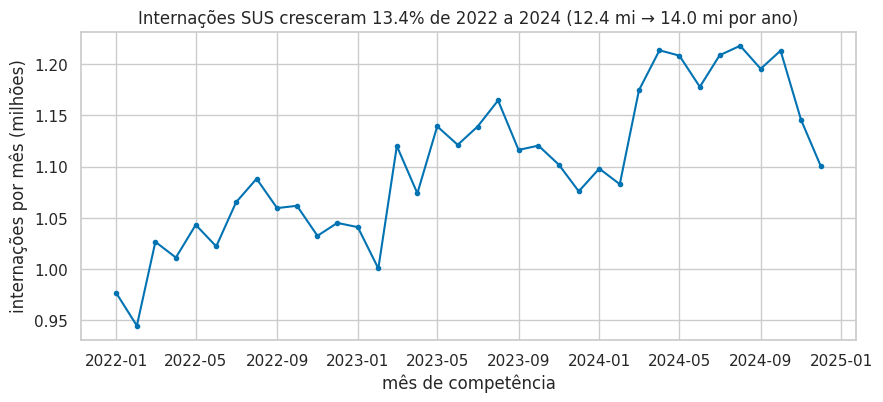

In [27]:
m = fato.groupBy("id_tempo").agg(F.sum("qtd_internacoes").alias("n")).orderBy("id_tempo").toPandas()
m["data"] = pd.to_datetime(m.id_tempo.astype(str), format="%Y%m")
anual = m.groupby(m.data.dt.year).n.sum()
cres = (anual[2024] / anual[2022] - 1) * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m.data, m.n / 1e6, marker="o", ms=3)
ax.set(title=f"Internações SUS cresceram {cres:.1f}% de 2022 a 2024 ({anual[2022]/1e6:.1f} mi → {anual[2024]/1e6:.1f} mi por ano)",
       ylabel="internações por mês (milhões)", xlabel="mês de competência")
salvar(fig, "01_internacoes_mensais")

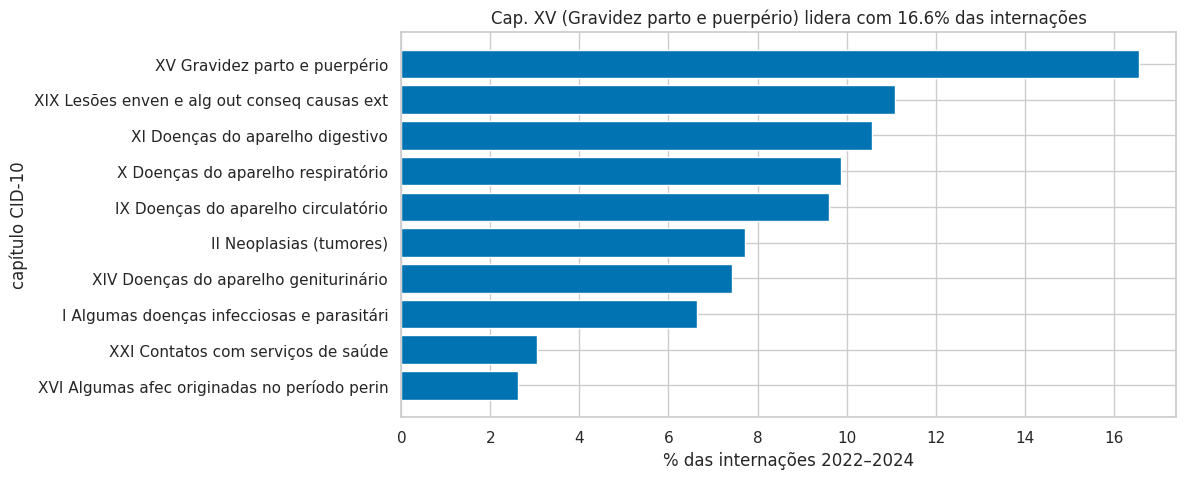

In [28]:
cap = (fato.groupBy("capitulo", "descricao").agg(F.sum("qtd_internacoes").alias("n")).toPandas()
       .sort_values("n", ascending=False))
cap["pct"] = cap.n / cap.n.sum() * 100
top = cap.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.capitulo + " " + top.descricao.str[:40], top.pct, color=sns.color_palette()[0])
ax.set(title=f"Cap. {cap.iloc[0].capitulo} ({cap.iloc[0].descricao[:30]}) lidera com {cap.iloc[0].pct:.1f}% das internações",
       xlabel="% das internações 2022–2024", ylabel="capítulo CID-10")
salvar(fig, "02_capitulos_cid")

<>:6: SyntaxWarning: invalid escape sequence '\$'
<>:6: SyntaxWarning: invalid escape sequence '\$'
<>:6: SyntaxWarning: invalid escape sequence '\$'
<>:6: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_690194/2417733190.py:6: SyntaxWarning: invalid escape sequence '\$'
  ax.set(title=f"Valor médio aprovado por internação vai de R\$ {fmt(v.vm.min())} ({v.iloc[-1].uf_hospital}) a R\$ {fmt(v.vm.max())} ({v.iloc[0].uf_hospital})",
/tmp/ipykernel_690194/2417733190.py:6: SyntaxWarning: invalid escape sequence '\$'
  ax.set(title=f"Valor médio aprovado por internação vai de R\$ {fmt(v.vm.min())} ({v.iloc[-1].uf_hospital}) a R\$ {fmt(v.vm.max())} ({v.iloc[0].uf_hospital})",


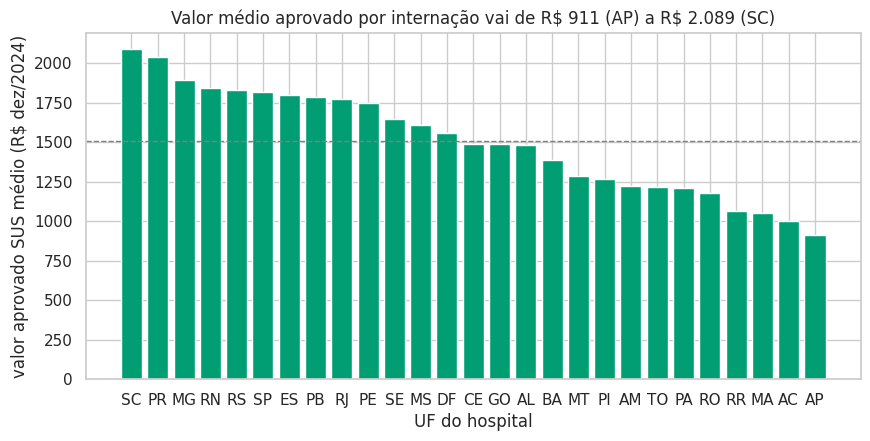

In [29]:
v = (fato.groupBy("uf_hospital").agg((F.sum("soma_val_tot_real") / F.sum("qtd_internacoes")).alias("vm"))
     .toPandas().sort_values("vm", ascending=False))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(v.uf_hospital, v.vm, color=sns.color_palette()[2])
ax.axhline(v.vm.mean(), ls="--", c="gray", lw=1)
ax.set(title=f"Valor médio aprovado por internação vai de R\$ {fmt(v.vm.min())} ({v.iloc[-1].uf_hospital}) a R\$ {fmt(v.vm.max())} ({v.iloc[0].uf_hospital})",
       ylabel="valor aprovado SUS médio (R$ dez/2024)", xlabel="UF do hospital")
salvar(fig, "03_valor_medio_uf_hospital")

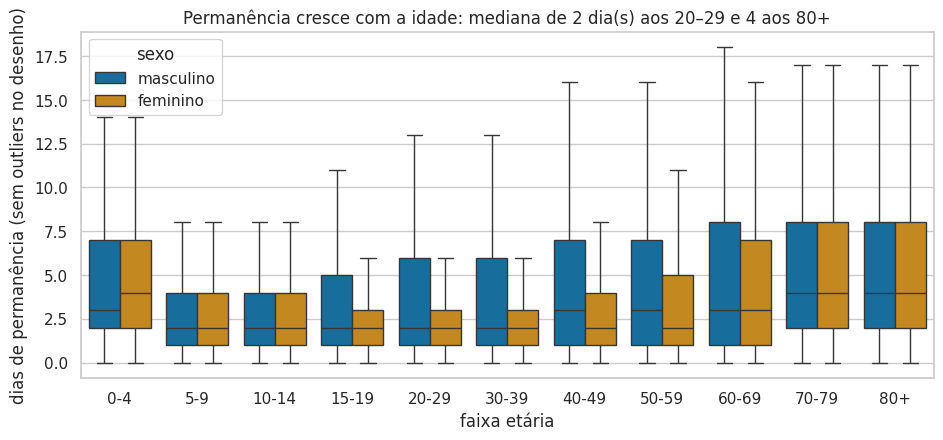

In [30]:
ordem = [f for f in g["dim_faixa_etaria"].orderBy("ordem").toPandas().faixa if f != "ignorado"]
a = amostra[amostra.faixa_etaria != "ignorado"]
med = a.groupby("faixa_etaria").dias_perm.median()
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=a, x="faixa_etaria", y="dias_perm", hue="sexo", order=ordem, showfliers=False, ax=ax)
ax.set(title=f"Permanência cresce com a idade: mediana de {med['20-29']:.0f} dia(s) aos 20–29 e {med['80+']:.0f} aos 80+",
       ylabel="dias de permanência (sem outliers no desenho)", xlabel="faixa etária")
salvar(fig, "04_permanencia_idade_sexo")

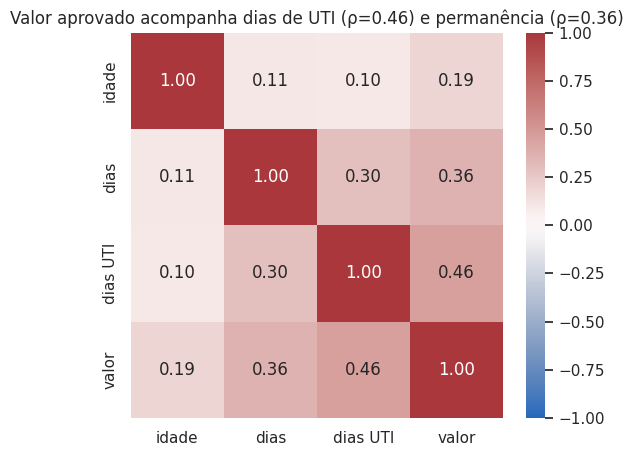

In [31]:
c = amostra[["idade_anos", "dias_perm", "uti_mes_to", "val_tot"]].dropna().corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(c, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax,
            xticklabels=["idade", "dias", "dias UTI", "valor"], yticklabels=["idade", "dias", "dias UTI", "valor"])
ax.set_title(f"Valor aprovado acompanha dias de UTI (ρ={c.loc['uti_mes_to','val_tot']:.2f}) e permanência (ρ={c.loc['dias_perm','val_tot']:.2f})")
salvar(fig, "05_correlacao")

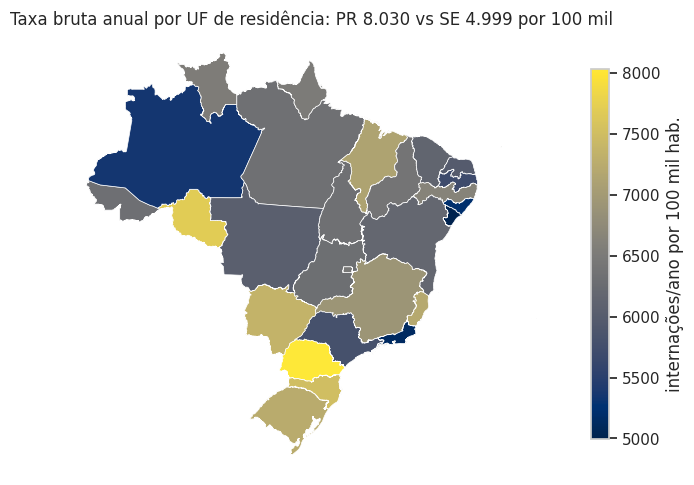

In [32]:
pop_uf = (g["populacao_municipio_ano"].join(g["dim_municipio"], "id_municipio").groupBy("uf", "ano")
          .agg(F.sum("populacao").alias("pop")).groupBy("uf").agg(F.avg("pop").alias("pop")))
# população anual média; fato soma 36 meses, então divide por 3 pra anualizar
taxa = (fato.groupBy(F.col("uf_res").alias("uf")).agg(F.sum("qtd_internacoes").alias("n")).join(pop_uf, "uf")
        .withColumn("taxa", F.col("n") / 3 / F.col("pop") * 1e5).toPandas())
uf_geo = gpd.read_file(BRONZE / "geo" / "uf.gpkg").merge(taxa, left_on="abbrev_state", right_on="uf")
hi, lo = taxa.loc[taxa.taxa.idxmax()], taxa.loc[taxa.taxa.idxmin()]
fig, ax = plt.subplots(figsize=(8, 8))
uf_geo.plot(column="taxa", cmap="cividis", legend=True, ax=ax, edgecolor="white", lw=0.5,
            legend_kwds={"label": "internações/ano por 100 mil hab.", "shrink": 0.6})
ax.set_axis_off()
ax.set_title(f"Taxa bruta anual por UF de residência: {hi.uf} {fmt(hi.taxa)} vs {lo.uf} {fmt(lo.taxa)} por 100 mil")
salvar(fig, "06_mapa_taxa_uf")

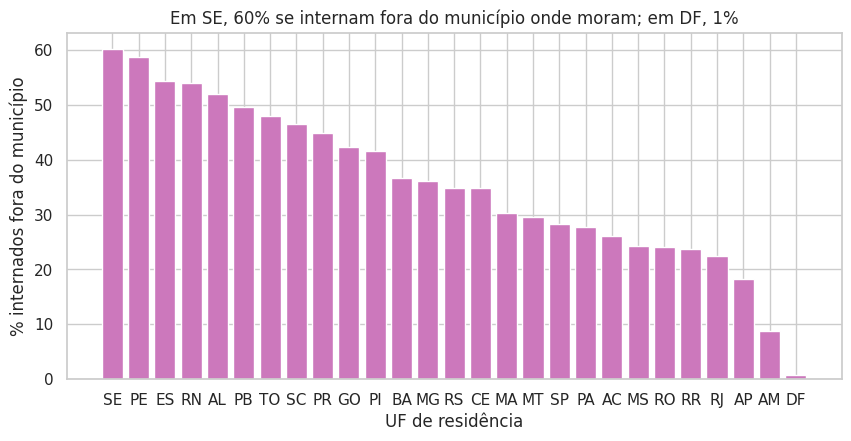

In [33]:
fora = (fato.groupBy(F.col("uf_res").alias("uf")).agg((F.sum("qtd_fora_municipio") / F.sum("qtd_internacoes") * 100).alias("pct"))
        .filter("uf != 'ignorado'").toPandas().sort_values("pct", ascending=False))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(fora.uf, fora.pct, color=sns.color_palette()[4])
ax.set(title=f"Em {fora.iloc[0].uf}, {fora.iloc[0].pct:.0f}% se internam fora do município onde moram; em {fora.iloc[-1].uf}, {fora.iloc[-1].pct:.0f}%",
       ylabel="% internados fora do município", xlabel="UF de residência")
salvar(fig, "07_fora_municipio")

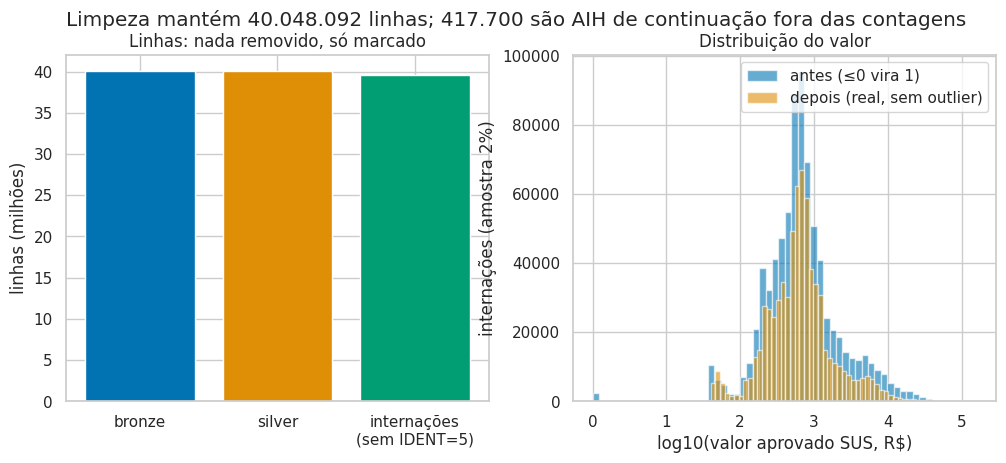

In [34]:
n_silver = int(spark.read.parquet(str(ROOT / "data" / "silver" / "sih_rd")).count())
n_fato = int(m.n.sum())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.bar(["bronze", "silver", "internações\n(sem IDENT=5)"], [N / 1e6, n_silver / 1e6, n_fato / 1e6], color=sns.color_palette()[:3])
a1.set(ylabel="linhas (milhões)", title="Linhas: nada removido, só marcado")
bruto = amostra.val_tot.fillna(0)
a2.hist(np.log10(bruto.clip(lower=1)), bins=60, alpha=0.6, label="antes (≤0 vira 1)")
a2.hist(np.log10(amostra.loc[~amostra.outlier_val_tot, "val_tot_real"].dropna()), bins=60, alpha=0.6, label="depois (real, sem outlier)")
a2.set(xlabel="log10(valor aprovado SUS, R$)", ylabel="internações (amostra 2%)", title="Distribuição do valor")
a2.legend()
fig.suptitle(f"Limpeza mantém {fmt(n_silver)} linhas; {fmt(N - n_fato)} são AIH de continuação fora das contagens")
salvar(fig, "08_antes_depois")

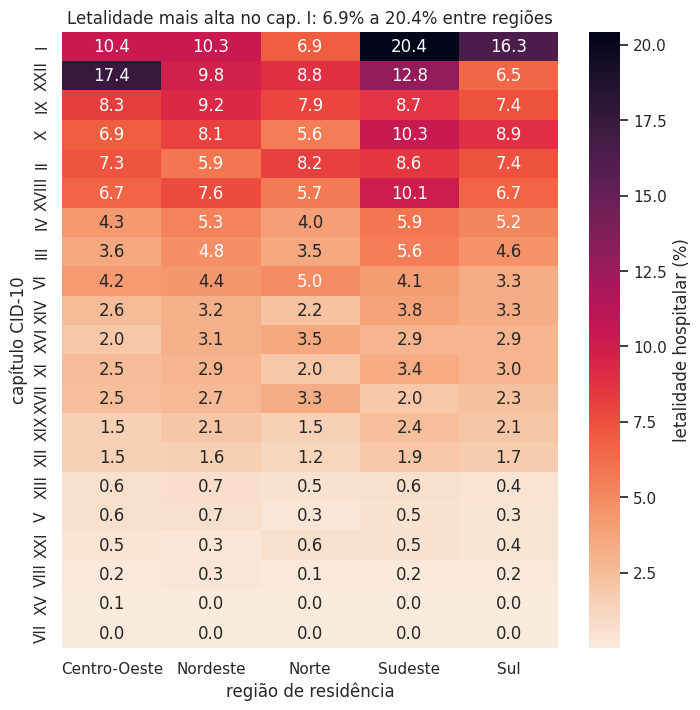

In [35]:
l = (fato.filter("regiao_res != 'ignorado'").groupBy("capitulo", "regiao_res")
     .agg((F.sum("qtd_obitos") / F.sum("qtd_internacoes") * 100).alias("let")).toPandas()
     .pivot(index="capitulo", columns="regiao_res", values="let"))
l = l.loc[l.mean(axis=1).sort_values(ascending=False).index]
topcap = l.mean(axis=1).idxmax()
fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(l, annot=True, fmt=".1f", cmap="rocket_r", ax=ax, cbar_kws={"label": "letalidade hospitalar (%)"})
ax.set(title=f"Letalidade mais alta no cap. {topcap}: {l.loc[topcap].min():.1f}% a {l.loc[topcap].max():.1f}% entre regiões",
       xlabel="região de residência", ylabel="capítulo CID-10")
salvar(fig, "09_letalidade_cid_regiao")

In [36]:
let_faixa = (fato.join(g["dim_faixa_etaria"], "id_faixa_etaria").groupBy("faixa", "ordem")
    .agg((F.sum("qtd_obitos") / F.sum("qtd_internacoes") * 100).alias("let")).orderBy("ordem").toPandas())
resp = pd.DataFrame({"pergunta": ["1 tendência", "2 causas", "3 valor aprovado", "4 permanência e óbito", "5 fora do município"],
    "resposta": [f"+{cres:.1f}% 2022→2024; taxa {hi.uf} {fmt(hi.taxa)} a {lo.uf} {fmt(lo.taxa)} por 100 mil",
                 f"cap. {cap.iloc[0].capitulo} {cap.iloc[0].pct:.1f}%",
                 f"R$ {fmt(v.vm.min())} ({v.iloc[-1].uf_hospital}) a R$ {fmt(v.vm.max())} ({v.iloc[0].uf_hospital})",
                 f"mediana {med['20-29']:.0f}→{med['80+']:.0f} dias; letalidade " + ", ".join(f"{r.faixa} {r.let:.1f}%" for r in let_faixa.itertuples()),
                 f"{fora.iloc[0].uf} {fora.iloc[0].pct:.0f}% … {fora.iloc[-1].uf} {fora.iloc[-1].pct:.0f}%"]})
pd.set_option("display.max_colwidth", 200)
resp

,pergunta,resposta
0,1 tendência,+13.4% 2022→2024; taxa PR 8.030 a SE 4.999 por 100 mil
1,2 causas,cap. XV 16.6%
2,3 valor aprovado,R$ 911 (AP) a R$ 2.089 (SC)
3,4 permanência e óbito,"mediana 2→4 dias; letalidade 0-4 1.6%, 5-9 0.4%, 10-14 0.5%, 15-19 0.5%, 20-29 0.6%, 30-39 1.2%, 40-49 2.7%, 50-59 4.8%, 60-69 7.4%, 70-79 11.0%, 80+ 18.4%, ignorado 7.5%"
4,5 fora do município,SE 60% … DF 1%
